# NYC Food Safety Inspection Model
*Predicting serious health-inspection failures in NYC restaurants*

## Part 1: Data Cleaning, Exploratory Data Analysis and Feature Engineering

**Research question:** Using only information available *before* an inspection, can we predict which New York City restaurants will receive a **serious failing score (28 points or more, the C-grade range)** at their next routine health inspection?

**How NYC scores inspections:** inspectors add points for each violation they find, so a *higher* score is *worse*. 0–13 points earns an A, 14–27 a B, and 28 or more a C.

**This notebook:**
1. Loads the raw NYC Open Data snapshot (one row per violation).
2. Cleans it: duplicates, placeholder dates, missing values, invalid locations.
3. Rolls violations up to one row per inspection.
4. Checks for outliers.
5. Builds features from each restaurant's *earlier* inspections only.
6. Explores the data visually and with statistical tests.
7. Saves a clean modeling table for the baseline model in [Part 2](02_baseline_model.ipynb).

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Plot styling used throughout the notebook
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

# File locations (relative to the notebooks/ folder)
RAW_PATH = Path("../data/raw/nyc_restaurant_inspections_2026-10-25.csv.gz")
PROCESSED_PATH = Path("../data/processed/model_table.csv.gz")
IMAGES_DIR = Path("../images")
IMAGES_DIR.mkdir(exist_ok=True)

FAIL_THRESHOLD = 28   # score of 28+ = C-grade range = "serious failure"
A_THRESHOLD = 14      # score of 14+ = not an A
FAIL_COLOR, PASS_COLOR = "#c0392b", "#2e86c1"


def save_fig(fig, name):
    """Save a figure to images/ so the README can show it."""
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 2. Load the data

The source is the **DOHMH New York City Restaurant Inspection Results** dataset from [NYC Open Data](https://data.cityofnewyork.us/Health/DOHMH-New-York-City-Restaurant-Inspection-Results/43nn-pn8j). The city updates it daily, so this project uses a fixed snapshot downloaded on **25 October 2026** (stored compressed in `data/raw/`) to keep the results reproducible.

Every column is read as text first so that codes such as ZIP codes and restaurant IDs keep their leading zeros. Types are converted in the cleaning step.

In [2]:
raw = pd.read_csv(RAW_PATH, dtype=str)
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Unique restaurants (CAMIS IDs): {raw['CAMIS'].nunique():,}")

Raw data: 294,406 rows x 27 columns
Unique restaurants (CAMIS IDs): 31,369


In [3]:
raw[["CAMIS", "DBA", "BORO", "CUISINE DESCRIPTION", "INSPECTION DATE", "VIOLATION CODE",
     "CRITICAL FLAG", "SCORE", "GRADE", "INSPECTION TYPE"]].head()

,CAMIS,DBA,BORO,CUISINE DESCRIPTION,INSPECTION DATE,VIOLATION CODE,CRITICAL FLAG,SCORE,GRADE,INSPECTION TYPE
0,40536414,LA CABANA,Brooklyn,Latin American,03/21/2023,08A,Not Critical,31,NaN,Cycle Inspection / Initial Inspection
1,50089033,THE LEGEND'S LOUNGE,Manhattan,NaN,01/01/1900,NaN,Not Applicable,NaN,NaN,NaN
2,41718673,BAREBURGER,Brooklyn,Hamburgers,01/08/2024,06D,Critical,52,NaN,Cycle Inspection / Initial Inspection
3,50108113,KAUSA,Manhattan,Peruvian,08/11/2025,09B,Not Critical,32,NaN,Cycle Inspection / Initial Inspection
4,41718493,ON TRACK BAR (OTB),Brooklyn,New American,12/04/2022,06D,Critical,18,NaN,Cycle Inspection / Initial Inspection


**Key columns.** Each row is *one violation* found during *one inspection*:

| Column | Meaning |
|---|---|
| `CAMIS` | Unique restaurant ID |
| `DBA` | Restaurant name ("doing business as") |
| `BORO`, `ZIPCODE`, `Latitude`, `Longitude`, `NTA` | Location (NTA = neighborhood) |
| `CUISINE DESCRIPTION` | Type of food served |
| `INSPECTION DATE`, `INSPECTION TYPE` | When and what kind of inspection (routine cycle, re-inspection, pre-permit, ...) |
| `ACTION` | Outcome, e.g., violations cited or establishment closed |
| `VIOLATION CODE`, `VIOLATION DESCRIPTION`, `CRITICAL FLAG` | The violation found and whether it is critical to food safety |
| `SCORE`, `GRADE` | Total inspection score (repeated on every violation row of that inspection) and letter grade |

## 3. Data cleaning
### 3.1 Standardize column names and data types

In [4]:
df = raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(" ", "_").str.replace("cuisine_description", "cuisine"))

df["inspection_date"] = pd.to_datetime(df["inspection_date"], format="%m/%d/%Y")
df["score"] = pd.to_numeric(df["score"], errors="coerce")
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
df.dtypes.to_frame("dtype").T

,camis,dba,boro,building,street,zipcode,phone,cuisine,inspection_date,action,violation_code,violation_description,critical_flag,score,grade,grade_date,record_date,inspection_type,latitude,longitude,community_board,council_district,census_tract,bin,bbl,nta,location
dtype,str,str,str,str,str,str,str,str,datetime64[us],str,str,str,str,float64,str,str,str,str,float64,float64,str,str,str,str,str,str,str


### 3.2 Are there duplicate rows?

In [5]:
n_dupes = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Removed {n_dupes:,} exact duplicate rows -> {len(df):,} rows remain")

Removed 217 exact duplicate rows -> 294,189 rows remain


### 3.3 Placeholder dates: restaurants that have not been inspected yet

The city lists newly permitted restaurants with an inspection date of **1 January 1900** until their first inspection. These rows contain no inspection, so they are removed.

The dataset also keeps only a rolling window of recent inspections: coverage before 2022 is very thin, as the chart below shows. To keep the analysis consistent, I keep inspections from **1 January 2022** onward.

Placeholder (1900) rows: 3,917 (3,917 restaurants)


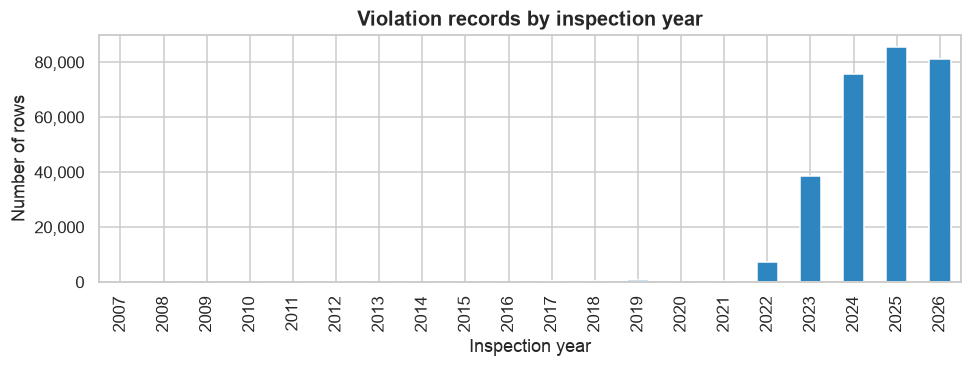

In [6]:
placeholder = df["inspection_date"].dt.year == 1900
print(f"Placeholder (1900) rows: {placeholder.sum():,} ({df.loc[placeholder, 'camis'].nunique():,} restaurants)")
df = df[~placeholder]

fig, ax = plt.subplots(figsize=(9, 3.5))
df["inspection_date"].dt.year.value_counts().sort_index().plot.bar(ax=ax, color=PASS_COLOR)
ax.set(title="Violation records by inspection year", xlabel="Inspection year", ylabel="Number of rows")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout()
plt.show()

In [7]:
before_2022 = df["inspection_date"] < "2022-01-01"
print(f"Rows before 2022 removed: {before_2022.sum():,} ({before_2022.mean():.1%} of rows)")
df = df[~before_2022]
print(f"Date range kept: {df['inspection_date'].min():%d %b %Y} to {df['inspection_date'].max():%d %b %Y}")

Rows before 2022 removed: 2,255 (0.8% of rows)
Date range kept: 04 Jan 2022 to 21 Oct 2026


### 3.4 Missing and invalid values

Some columns are missing *by design*, so each one needs its own decision.

In [8]:
# Coordinates of 0 are not real locations in NYC: treat them as missing
df.loc[(df["latitude"] == 0) | (df["longitude"] == 0), ["latitude", "longitude"]] = np.nan
# Borough "0" is not a real borough: treat it as missing
df.loc[df["boro"] == "0", "boro"] = np.nan

missing = (df.isna().mean().mul(100).round(1).sort_values(ascending=False)
           .to_frame("% missing").query("`% missing` > 0"))
missing.T

,grade_date,grade,score,bin,nta,census_tract,council_district,community_board,longitude,latitude,location,violation_description,violation_code,zipcode,bbl,building,boro
% missing,53.900,50.300,4.600,1.900,1.500,1.500,1.500,1.500,1.500,1.500,1.500,1.000,1.000,1.000,0.500,0.300,0.100


| Column | Why it is missing | Decision |
|---|---|---|
| `grade`, `grade_date` | Grades are only issued on some inspections (e.g., not on initial inspections that score 14+, which get a re-inspection first) | Not used as a feature, so left as is |
| Location columns (`nta`, `census_tract`, `bin`, ...) | Address could not be geocoded | Fill latitude/longitude and borough from other records with the same ZIP code; the rest are not needed |
| `violation_code`, `violation_description` | Inspections where **no violations** were found | Keep: these are clean inspections, counted as 0 violations |
| `score` | Inspection types that are not scored (e.g., smoke-free or calorie-posting checks) | Keep for history counts; the target uses only scored routine inspections |
| `cuisine` | Not recorded | Fill with "Not Listed" |
| `zipcode` | Not recorded | Left missing; only used to fill other location fields |

In [9]:
# Impute borough and coordinates from other restaurants in the same ZIP code
zip_lookup = (df.dropna(subset=["zipcode"])
              .groupby("zipcode")
              .agg(zip_boro=("boro", lambda s: s.mode().iat[0] if s.notna().any() else np.nan),
                   zip_lat=("latitude", "median"), zip_lon=("longitude", "median")))
df = df.join(zip_lookup, on="zipcode")
filled_boro = df["boro"].isna() & df["zip_boro"].notna()
df["boro"] = df["boro"].fillna(df["zip_boro"])
df["latitude"] = df["latitude"].fillna(df["zip_lat"])
df["longitude"] = df["longitude"].fillna(df["zip_lon"])
df = df.drop(columns=["zip_boro", "zip_lat", "zip_lon"])

df["cuisine"] = df["cuisine"].fillna("Not Listed")

# Rows whose borough is still unknown cannot be placed anywhere: drop them
still_missing_boro = df["boro"].isna()
df = df[~still_missing_boro]
print(f"Borough filled from ZIP code: {filled_boro.sum():,} rows; dropped (no borough): {still_missing_boro.sum():,} rows")
print(f"Rows still missing coordinates: {df['latitude'].isna().sum():,}")
print(f"Clean violation-level data: {len(df):,} rows, {df['camis'].nunique():,} restaurants")

Borough filled from ZIP code: 42 rows; dropped (no borough): 195 rows
Rows still missing coordinates: 3,010
Clean violation-level data: 287,822 rows, 27,214 restaurants


## 4. From violations to inspections

The model predicts the outcome of an **inspection**, so the violation rows are rolled up to one row per restaurant, date and inspection type. Along the way I tag the violation families that matter most for food safety, based on the city's violation codes:

| Family | Codes | Examples |
|---|---|---|
| **Pests** | 04K, 04L, 04M, 04N | Rats, mice, live roaches, filth flies |
| **Pest-friendly conditions** | 08A | Gaps, clutter or harborage that let pests in |
| **Food temperature** | 02A–02J | Cold food held above 41 °F, hot food below 140 °F |
| **Contamination and hygiene** | 06A–06F | Food not protected, surfaces not sanitized |
| **No certified food manager** | 04A | No one on site holds a Food Protection Certificate |

In [10]:
code = df["violation_code"].fillna("")
df["is_critical"] = df["critical_flag"].eq("Critical")
df["is_pest"] = code.isin(["04K", "04L", "04M", "04N"])
df["is_harborage"] = code.eq("08A")
df["is_temperature"] = code.str.startswith("02")
df["is_hygiene"] = code.str.startswith("06")
df["is_no_fpc"] = code.eq("04A")
df["is_closure"] = df["action"].fillna("").str.contains("Closed by DOHMH")

inspections = (df.groupby(["camis", "inspection_date", "inspection_type"], dropna=False)
               .agg(dba=("dba", "first"), boro=("boro", "first"), zipcode=("zipcode", "first"),
                    cuisine=("cuisine", "first"), latitude=("latitude", "first"),
                    longitude=("longitude", "first"), score=("score", "max"),
                    n_violations=("violation_code", "count"), n_critical=("is_critical", "sum"),
                    pest=("is_pest", "any"), harborage=("is_harborage", "any"),
                    temperature=("is_temperature", "any"), hygiene=("is_hygiene", "any"),
                    no_fpc=("is_no_fpc", "any"), closed=("is_closure", "any"))
               .reset_index())

# Split "Cycle Inspection / Initial Inspection" into program and visit type
inspections[["program", "visit"]] = inspections["inspection_type"].str.split(" / ", n=1, expand=True)
print(f"{len(inspections):,} inspections of {inspections['camis'].nunique():,} restaurants")
inspections["inspection_type"].value_counts().head(6).to_frame("inspections")

91,745 inspections of 27,214 restaurants


,inspections
inspection_type,
Cycle Inspection / Initial Inspection,46077
Cycle Inspection / Re-inspection,17048
Pre-permit (Operational) / Initial Inspection,10164
Administrative Miscellaneous / Initial Inspection,7234
Pre-permit (Operational) / Re-inspection,3049
Administrative Miscellaneous / Re-inspection,1310


**Prediction target.** NYC inspects every restaurant on a regular cycle. The first visit of each cycle (**Cycle Inspection / Initial Inspection**) is unannounced and decides whether the restaurant gets a follow-up. That is the moment the city wants to predict, so these are the rows the model will learn from. A score of **28 or more** is labelled a serious failure (`fail = 1`).

In [11]:
cycle = inspections[inspections["inspection_type"] == "Cycle Inspection / Initial Inspection"].copy()
print(f"Routine (cycle initial) inspections: {len(cycle):,}; missing score: {cycle['score'].isna().sum():,}")
cycle = cycle.dropna(subset=["score"])
cycle["fail"] = (cycle["score"] >= FAIL_THRESHOLD).astype(int)
print(f"Serious failure rate: {cycle['fail'].mean():.1%} of {len(cycle):,} scored routine inspections")

Routine (cycle initial) inspections: 46,077; missing score: 0
Serious failure rate: 18.0% of 46,077 scored routine inspections


## 5. Outlier analysis
### 5.1 Inspection scores

IQR upper fence: 46.5 points -> 1,908 inspections above it (4.1%); scores over 100: 43


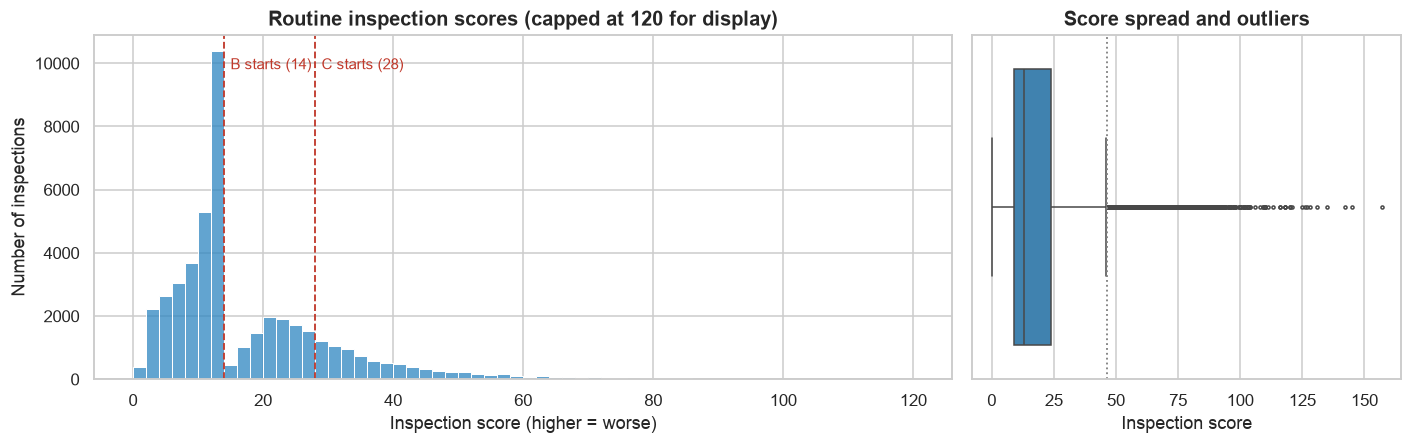

In [12]:
q1, q3 = cycle["score"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_above_fence = (cycle["score"] > upper_fence).sum()
print(f"IQR upper fence: {upper_fence:.1f} points -> {n_above_fence:,} inspections above it "
      f"({n_above_fence / len(cycle):.1%}); scores over 100: {(cycle['score'] > 100).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(cycle["score"].clip(upper=120), bins=60, ax=axes[0], color=PASS_COLOR)
for x, label in [(A_THRESHOLD, "B starts (14)"), (FAIL_THRESHOLD, "C starts (28)")]:
    axes[0].axvline(x, color=FAIL_COLOR, ls="--", lw=1.2)
    axes[0].text(x + 1, axes[0].get_ylim()[1] * 0.9, label, color=FAIL_COLOR, fontsize=10)
axes[0].set(title="Routine inspection scores (capped at 120 for display)",
            xlabel="Inspection score (higher = worse)", ylabel="Number of inspections")
sns.boxplot(x=cycle["score"], ax=axes[1], color=PASS_COLOR, fliersize=2)
axes[1].axvline(upper_fence, color="gray", ls=":", lw=1.2)
axes[1].set(title="Score spread and outliers", xlabel="Inspection score")
plt.tight_layout()
plt.show()

**What the chart shows:** most routine inspections score below 28, and the distribution has a long right tail. Notice the tall spike at **12–13 points**, just under the A cutoff: inspectors and restaurants both cluster right at the A/B boundary. The box plot flags 4.1% of inspections as statistical outliers (above 46.5 points).

Are the very high scores data errors, or real? A score is the sum of points for each violation, so a real high score should come with many violations.

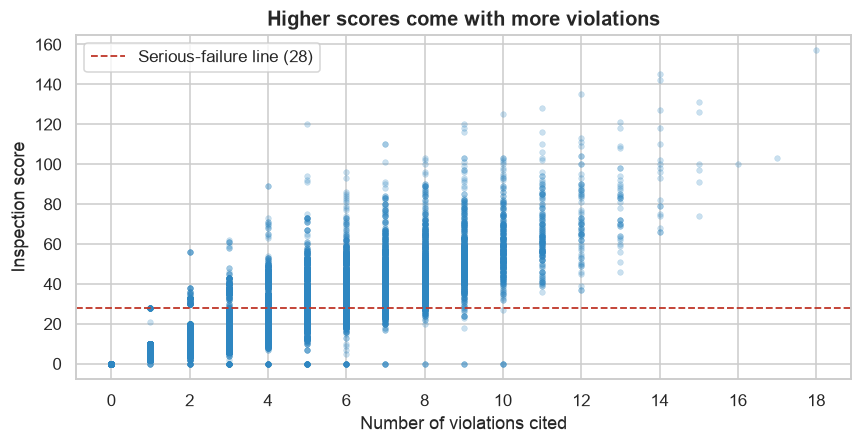

200 highest-scoring inspections: median 10 violations (vs 3 overall); closed 63% of the time


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.scatterplot(data=cycle, x="n_violations", y="score", alpha=0.25, s=14, ax=ax, color=PASS_COLOR, edgecolor=None)
ax.axhline(FAIL_THRESHOLD, color=FAIL_COLOR, ls="--", lw=1.2, label="Serious-failure line (28)")
ax.set(title="Higher scores come with more violations", xlabel="Number of violations cited", ylabel="Inspection score")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

top = cycle.nlargest(200, "score")
print(f"200 highest-scoring inspections: median {top['n_violations'].median():.0f} violations "
      f"(vs {cycle['n_violations'].median():.0f} overall); closed {top['closed'].mean():.0%} of the time")

**Decision.** The extreme scores line up with many violations and frequent closures, so they are **genuine bad inspections, not errors**, and they stay in the target. Because a single extreme past score could dominate a linear model, history features built from past scores are **capped at the 99th percentile** in the next section.

### 5.2 Anomaly: zero scores despite violations

The scatter plot also shows inspections at **0 points** even though several violations were cited. Critical violations always carry points, so a zero score with critical violations is impossible and points to a data-entry error.

In [14]:
zero_score_anomaly = (cycle["score"] == 0) & (cycle["n_critical"] > 0)
print(f"Zero-score inspections with critical violations: {zero_score_anomaly.sum():,} "
      f"({zero_score_anomaly.mean():.2%} of routine inspections)")
cycle = cycle[~zero_score_anomaly]
print(f"Removed as unreliable labels -> {len(cycle):,} routine inspections; failure rate {cycle['fail'].mean():.1%}")

Zero-score inspections with critical violations: 77 (0.17% of routine inspections)
Removed as unreliable labels -> 46,000 routine inspections; failure rate 18.1%


## 6. Feature engineering

Every feature must be something an inspector could know **before** the visit. Each restaurant's history is therefore built only from inspections on **earlier dates**: the result being predicted is never used.

1. Collapse all inspections (any type) to one row per restaurant per day.
2. Compute running totals and "last time" values, shifted by one visit so the current day is excluded.
3. Attach those history features to each routine inspection.

In [15]:
daily = (inspections.sort_values(["camis", "inspection_date"])
         .groupby(["camis", "inspection_date"])
         .agg(score=("score", "max"), n_critical=("n_critical", "sum"), pest=("pest", "any"),
              harborage=("harborage", "any"), temperature=("temperature", "any"),
              hygiene=("hygiene", "any"), no_fpc=("no_fpc", "any"), closed=("closed", "any"))
         .reset_index())
by_restaurant = daily.groupby("camis")

daily["n_prior_inspections"] = by_restaurant.cumcount()
daily["days_since_last_inspection"] = by_restaurant["inspection_date"].diff().dt.days
# Most recent earlier score (skipping unscored visits) and the average of all earlier scores
daily["last_score"] = by_restaurant["score"].transform(lambda s: s.shift().ffill())
daily["prior_mean_score"] = by_restaurant["score"].transform(lambda s: s.shift().expanding().mean())
daily["last_n_critical"] = by_restaurant["n_critical"].shift()
# Running counts of earlier visits with each problem (current visit excluded)
for col in ["pest", "harborage", "temperature", "hygiene", "no_fpc", "closed"]:
    daily[f"prior_{col}_visits"] = by_restaurant[col].cumsum() - daily[col]
daily["last_had_pest"] = by_restaurant["pest"].shift().astype(float)

history_cols = ["n_prior_inspections", "days_since_last_inspection", "last_score", "prior_mean_score",
                "last_n_critical", "prior_pest_visits", "prior_harborage_visits", "prior_temperature_visits",
                "prior_hygiene_visits", "prior_no_fpc_visits", "prior_closed_visits", "last_had_pest"]
model_df = cycle.merge(daily[["camis", "inspection_date"] + history_cols], on=["camis", "inspection_date"], how="left")

Next, features about the previous **routine** inspection specifically, plus restaurant and calendar features:

* `prev_cycle_score`, `prev_cycle_fail`, `days_since_prev_cycle`: how the last unannounced routine visit went, and how long ago.
* `chain_size`: how many NYC locations share the restaurant's name (chains may have stronger standard procedures).
* `cuisine_group`: the 15 most common cuisines, with the rest grouped as "Other".
* `inspection_month`, `inspection_dow`: season and day of the week.

In [16]:
model_df = model_df.sort_values(["camis", "inspection_date"])
by_cycle = model_df.groupby("camis")
model_df["prev_cycle_score"] = by_cycle["score"].shift()
model_df["prev_cycle_fail"] = by_cycle["fail"].shift()
model_df["days_since_prev_cycle"] = by_cycle["inspection_date"].diff().dt.days
model_df["has_prior_inspection"] = (model_df["n_prior_inspections"] > 0).astype(int)

# Chain size: count distinct restaurant IDs per normalized name
name_key = df.drop_duplicates("camis").assign(name=lambda d: d["dba"].str.upper().str.strip())
chain_sizes = name_key.groupby("name")["camis"].nunique()
model_df["chain_size"] = model_df["dba"].str.upper().str.strip().map(chain_sizes).fillna(1).astype(int)
model_df["is_chain"] = (model_df["chain_size"] >= 5).astype(int)

top_cuisines = model_df["cuisine"].value_counts().head(15).index
model_df["cuisine_group"] = model_df["cuisine"].where(model_df["cuisine"].isin(top_cuisines), "Other")
model_df["inspection_month"] = model_df["inspection_date"].dt.month
model_df["inspection_dow"] = model_df["inspection_date"].dt.day_name()

# Cap score-based history features at the 99th percentile (see the outlier analysis)
for col in ["last_score", "prior_mean_score", "prev_cycle_score"]:
    cap = model_df[col].quantile(0.99)
    model_df[col] = model_df[col].clip(upper=cap)
    print(f"{col}: capped at {cap:.0f} points")

last_score: capped at 44 points
prior_mean_score: capped at 45 points
prev_cycle_score: capped at 70 points


In [17]:
print(f"Modeling table: {model_df.shape[0]:,} routine inspections x {model_df.shape[1]} columns")
print(f"With at least one earlier inspection: {model_df['has_prior_inspection'].mean():.1%}; "
      f"with an earlier routine inspection: {model_df['prev_cycle_score'].notna().mean():.1%}")
model_df[["camis", "inspection_date", "score", "fail", "last_score", "prev_cycle_score",
          "prior_pest_visits", "days_since_last_inspection", "chain_size", "cuisine_group"]].head()

Modeling table: 46,000 routine inspections x 42 columns
With at least one earlier inspection: 70.4%; with an earlier routine inspection: 52.1%


,camis,inspection_date,score,fail,last_score,prev_cycle_score,prior_pest_visits,days_since_last_inspection,chain_size,cuisine_group
0,30075445,2023-08-01,38.000,1,NaN,NaN,0,NaN,1,Bakery Products/Desserts
1,30075445,2024-11-08,10.000,0,12.000,38.000,2,444.000,1,Bakery Products/Desserts
2,30075445,2026-02-27,7.000,0,10.000,10.000,2,476.000,1,Bakery Products/Desserts
3,30191841,2024-11-20,24.000,0,NaN,NaN,0,NaN,1,Other
4,30191841,2026-07-30,13.000,0,10.000,24.000,1,525.000,1,Other


Missing history values are expected: a restaurant's first-ever inspection has no earlier score. They are **left as missing here** and imputed inside the modeling pipeline in Part 2 (median value plus a "was missing" flag), so that the imputation is learned from the training data only.

## 7. Exploratory data analysis
### 7.1 How common are serious failures?

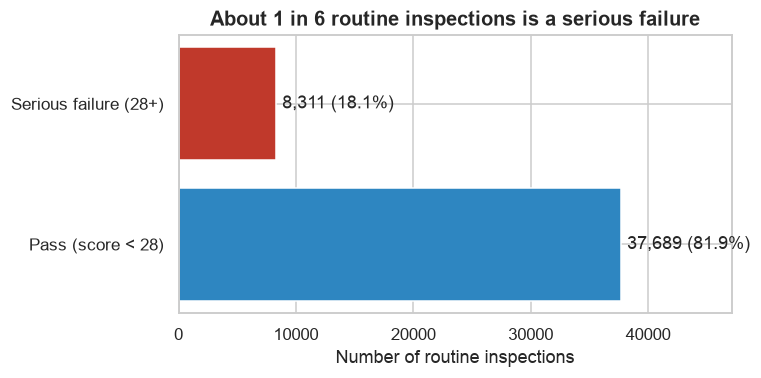

In [18]:
fail_counts = model_df["fail"].map({0: "Pass (score < 28)", 1: "Serious failure (28+)"}).value_counts()
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(fail_counts.index, fail_counts.values, color=[PASS_COLOR, FAIL_COLOR])
ax.bar_label(bars, labels=[f"{v:,} ({v / fail_counts.sum():.1%})" for v in fail_counts.values], padding=4)
ax.set(title="About 1 in 6 routine inspections is a serious failure", xlabel="Number of routine inspections")
ax.set_xlim(0, fail_counts.max() * 1.25)
plt.tight_layout()
plt.show()

The classes are **imbalanced**: a model that always predicts "pass" would be right about 83% of the time while catching *no* failures. This is why Part 2 uses precision-recall based metrics rather than accuracy.

### 7.2 Where and what: borough and cuisine

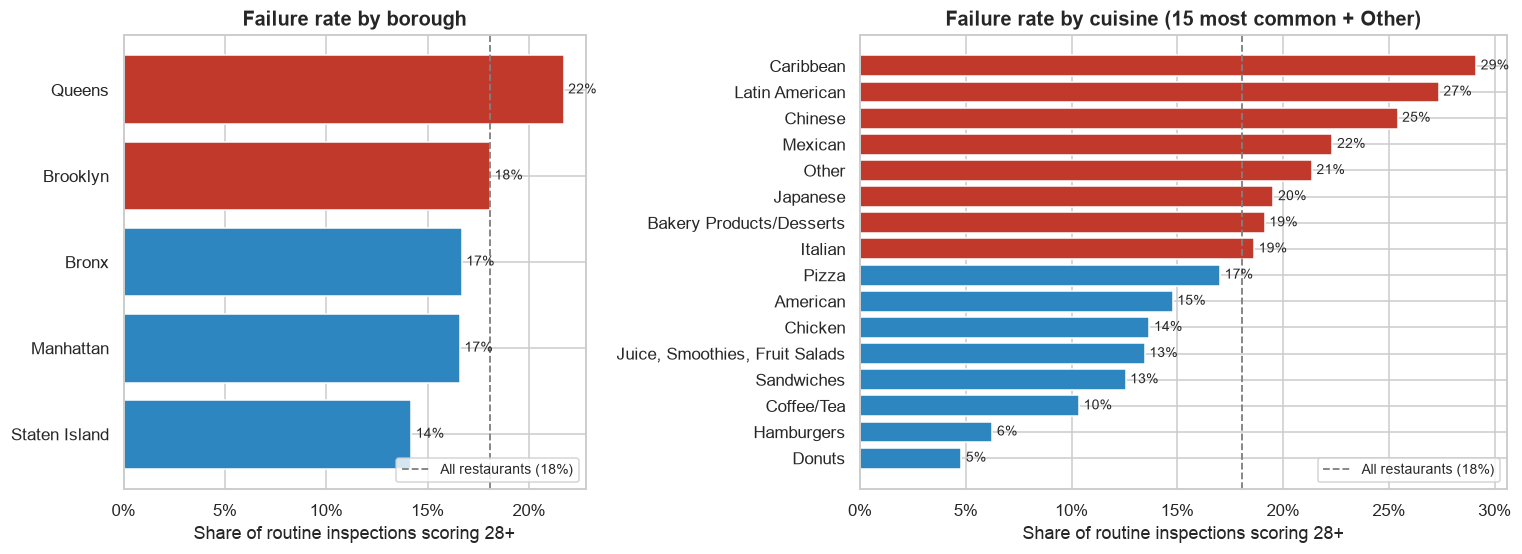

In [19]:
def failure_rate_table(data, col, min_n=1):
    """Failure rate and inspection count per category, sorted by failure rate."""
    out = data.groupby(col)["fail"].agg(fail_rate="mean", inspections="size")
    return out[out["inspections"] >= min_n].sort_values("fail_rate")


overall_rate = model_df["fail"].mean()
boro_rates = failure_rate_table(model_df, "boro")
cuisine_rates = failure_rate_table(model_df, "cuisine_group")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})
for ax, rates, title in [(axes[0], boro_rates, "Failure rate by borough"),
                         (axes[1], cuisine_rates, "Failure rate by cuisine (15 most common + Other)")]:
    colors = [FAIL_COLOR if r > overall_rate else PASS_COLOR for r in rates["fail_rate"]]
    bars = ax.barh(rates.index, rates["fail_rate"], color=colors)
    ax.bar_label(bars, labels=[f"{r:.0%}" for r in rates["fail_rate"]], padding=3, fontsize=9)
    ax.axvline(overall_rate, color="gray", ls="--", lw=1.2, label=f"All restaurants ({overall_rate:.0%})")
    ax.set(title=title, xlabel="Share of routine inspections scoring 28+", ylabel="")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig(fig, "failure_by_borough_cuisine")
plt.show()

**Observations:**
* **Borough** matters a little: Queens has the highest serious-failure rate (22%) and Staten Island the lowest (14%).
* **Cuisine** matters much more: Caribbean (29%), Latin American (27%) and Chinese (25%) restaurants fail most often, while Donuts (5%), Hamburgers (6%) and Coffee/Tea (10%) rarely do. The low-failure groups are mostly counter-service formats with simpler food handling and many chain outlets, so cuisine is probably standing in for *kitchen complexity* and *chain status* rather than the food itself.

### 7.3 Does a restaurant's past predict its next inspection?

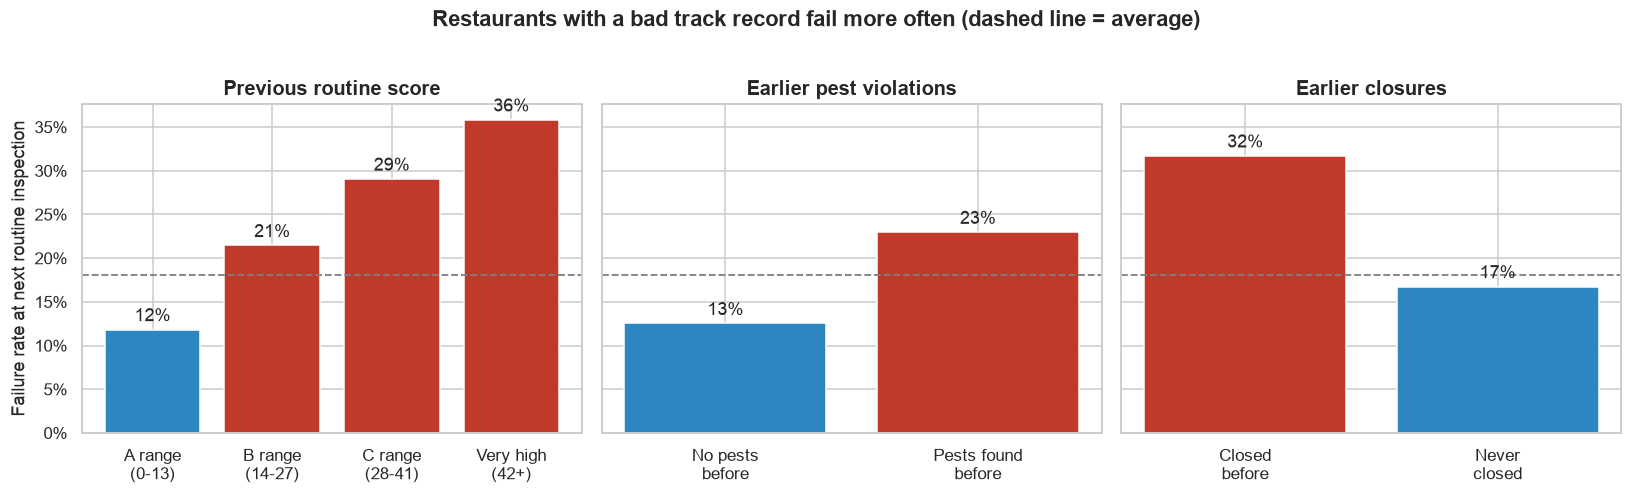

In [20]:
hist = model_df.dropna(subset=["prev_cycle_score"]).copy()
hist["prev_score_band"] = pd.cut(hist["prev_cycle_score"], bins=[-1, 13, 27, 41, 1000],
                                 labels=["A range\n(0-13)", "B range\n(14-27)", "C range\n(28-41)", "Very high\n(42+)"])
hist["pest_history"] = np.where(hist["prior_pest_visits"] > 0, "Pests found\nbefore", "No pests\nbefore")
hist["closure_history"] = np.where(hist["prior_closed_visits"] > 0, "Closed\nbefore", "Never\nclosed")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, col, title in [(axes[0], "prev_score_band", "Previous routine score"),
                       (axes[1], "pest_history", "Earlier pest violations"),
                       (axes[2], "closure_history", "Earlier closures")]:
    rates = hist.groupby(col, observed=True)["fail"].mean()
    bars = ax.bar(rates.index.astype(str), rates.values,
                  color=[FAIL_COLOR if r > overall_rate else PASS_COLOR for r in rates.values])
    ax.bar_label(bars, labels=[f"{r:.0%}" for r in rates.values], padding=3)
    ax.axhline(overall_rate, color="gray", ls="--", lw=1.2)
    ax.set(title=title, xlabel="")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("Failure rate at next routine inspection")
fig.suptitle("Restaurants with a bad track record fail more often (dashed line = average)", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "history_vs_failure")
plt.show()

**Observations** (restaurants with at least one earlier routine inspection):
* The worse the previous routine score, the higher the chance of failing again: from **12%** after an A-range score to **36%** after a very high score, three times as likely.
* Restaurants cited for **pests** before fail **23%** of the time vs **13%** for those never cited.
* Restaurants **closed** by the Health Department before fail **32%** of the time vs **17%**.

Past behavior is the strongest signal in the data, which supports building the model on inspection history.

### 7.4 Numeric features: failures vs passes

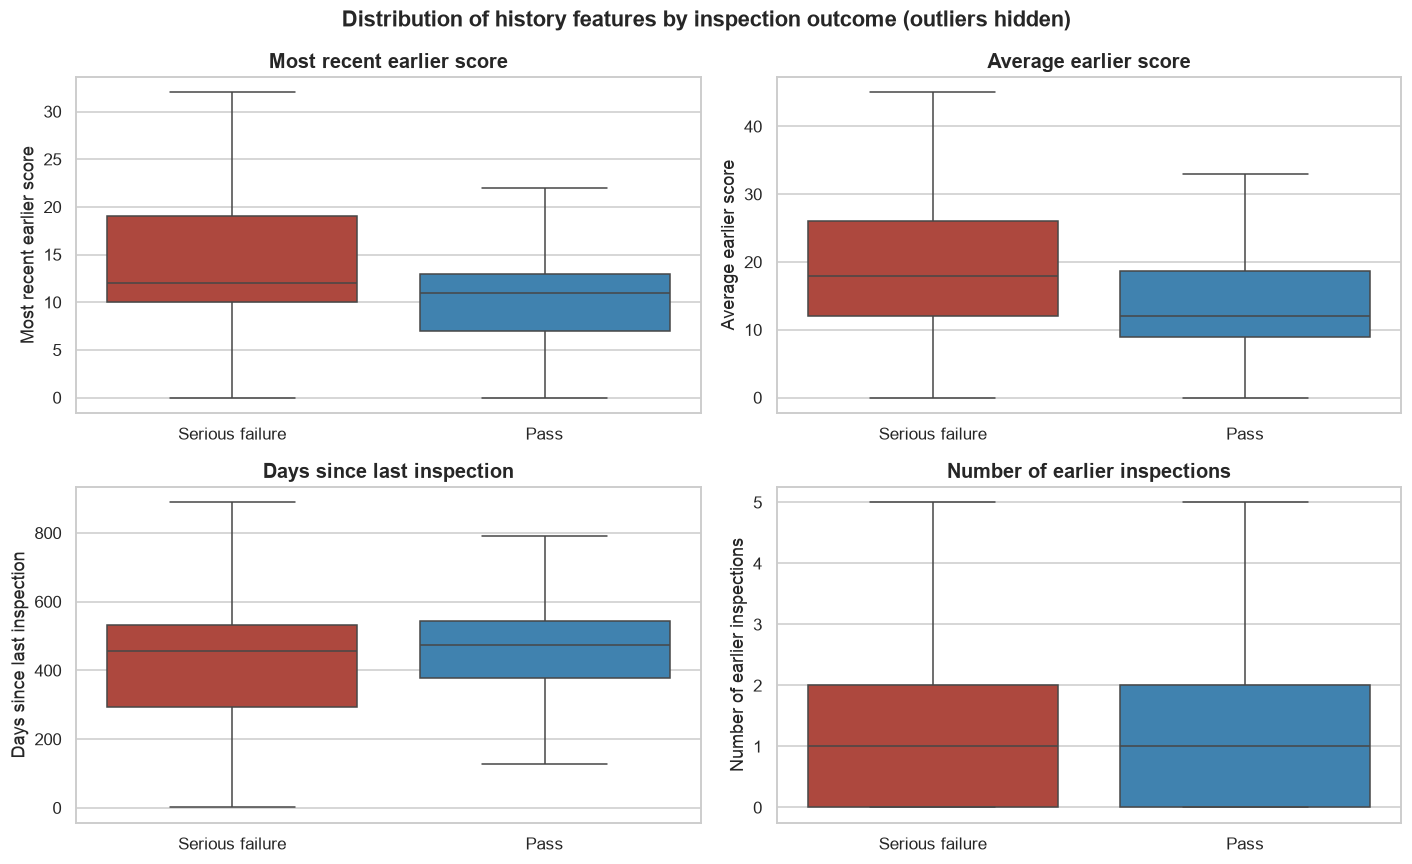

In [21]:
numeric_view = ["last_score", "prior_mean_score", "days_since_last_inspection", "n_prior_inspections"]
labels = {"last_score": "Most recent earlier score", "prior_mean_score": "Average earlier score",
          "days_since_last_inspection": "Days since last inspection", "n_prior_inspections": "Number of earlier inspections"}
plot_df = model_df.assign(outcome=model_df["fail"].map({0: "Pass", 1: "Serious failure"}))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, numeric_view):
    sns.boxplot(data=plot_df, x="outcome", y=col, hue="outcome", ax=ax, showfliers=False,
                palette={"Pass": PASS_COLOR, "Serious failure": FAIL_COLOR}, legend=False)
    ax.set(title=labels[col], xlabel="", ylabel=labels[col])
fig.suptitle("Distribution of history features by inspection outcome (outliers hidden)", fontweight="bold")
plt.tight_layout()
plt.show()

**Observations:** failing inspections follow higher earlier scores (median average earlier score 18 vs 12 points). Failures also come slightly *sooner* after the previous inspection (median 455 vs 474 days). That is partly because the city already re-visits poorly scoring restaurants more often, so this feature carries some of the city's own risk judgement. The number of earlier inspections looks similar for both groups.

### 7.5 How are the numeric features related?

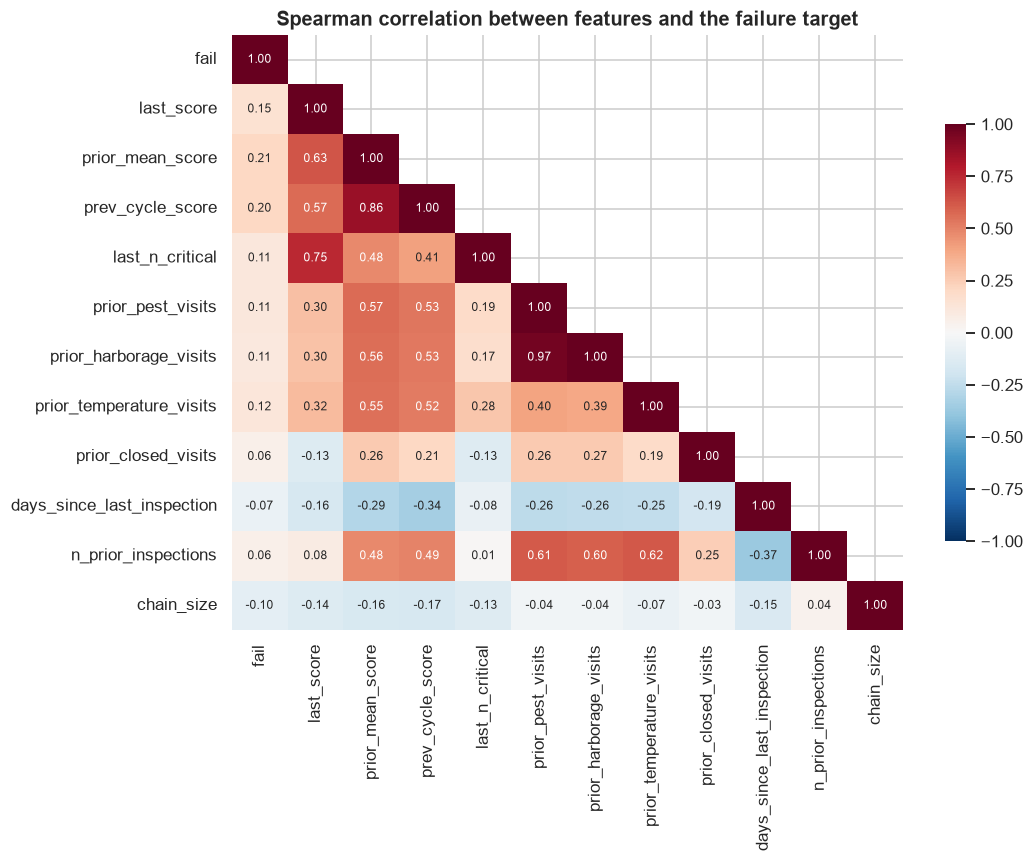

In [22]:
corr_cols = ["fail", "last_score", "prior_mean_score", "prev_cycle_score", "last_n_critical",
             "prior_pest_visits", "prior_harborage_visits", "prior_temperature_visits", "prior_closed_visits",
             "days_since_last_inspection", "n_prior_inspections", "chain_size"]
corr = model_df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8}, cbar_kws={"shrink": 0.7})
ax.set_title("Spearman correlation between features and the failure target")
plt.tight_layout()
plt.show()

**Observations:**
* Every single feature is only weakly correlated with the target (|r| ≤ 0.21), so no single number predicts failure. A model needs to **combine** several weak signals.
* `prior_pest_visits` and `prior_harborage_visits` are almost identical (r = 0.97), because inspectors nearly always cite pest-friendly conditions (08A) alongside pests. Only `prior_pest_visits` will be used in the model, to avoid redundant features.
* The three score-history features are strongly related to each other (r = 0.56–0.86). Regularization in the model will help handle this overlap.
* Larger chains fail less (negative correlation with `chain_size`).

### 7.6 Where are failures concentrated?

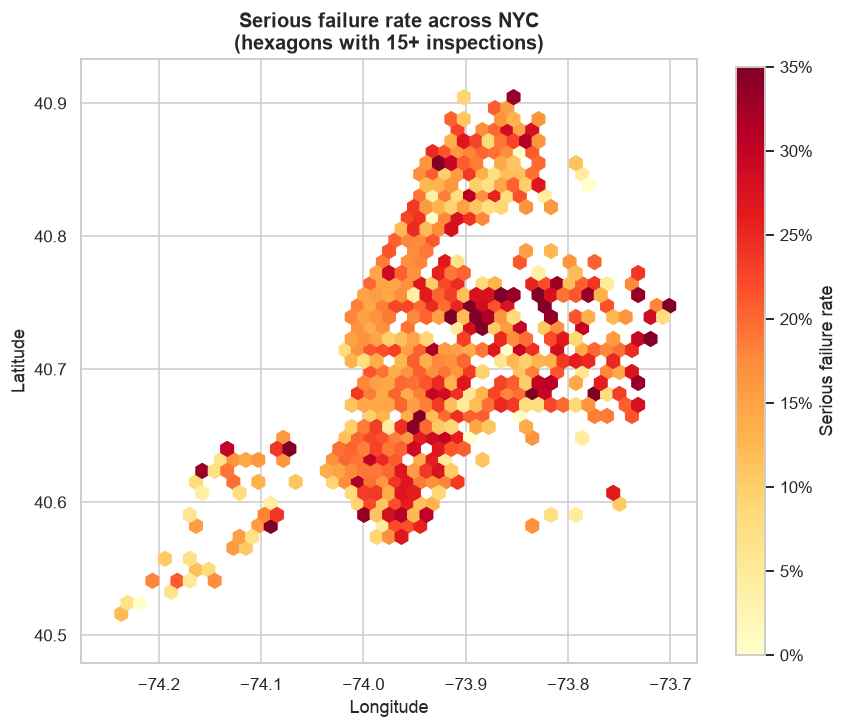

In [23]:
geo = model_df.dropna(subset=["latitude", "longitude"])
geo = geo[geo["latitude"].between(40.49, 40.92) & geo["longitude"].between(-74.27, -73.68)]
fig, ax = plt.subplots(figsize=(8, 8))
hb = ax.hexbin(geo["longitude"], geo["latitude"], C=geo["fail"], reduce_C_function=np.mean,
               gridsize=45, mincnt=15, cmap="YlOrRd", vmin=0, vmax=0.35)
fig.colorbar(hb, ax=ax, shrink=0.7, label="Serious failure rate", format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Serious failure rate across NYC\n(hexagons with 15+ inspections)", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1.3)
plt.tight_layout()
save_fig(fig, "failure_map")
plt.show()

**Observations:** failure rates vary block by block rather than following borough lines. The darkest clusters are in parts of **Queens** (around Flushing, Elmhurst and Jackson Heights) and **south Brooklyn**, areas with many independent restaurants. Location can help as a feature, but borough alone is too coarse to capture it; neighborhood-level features are worth testing in Module 24.

### 7.7 Which violations show up in serious failures?

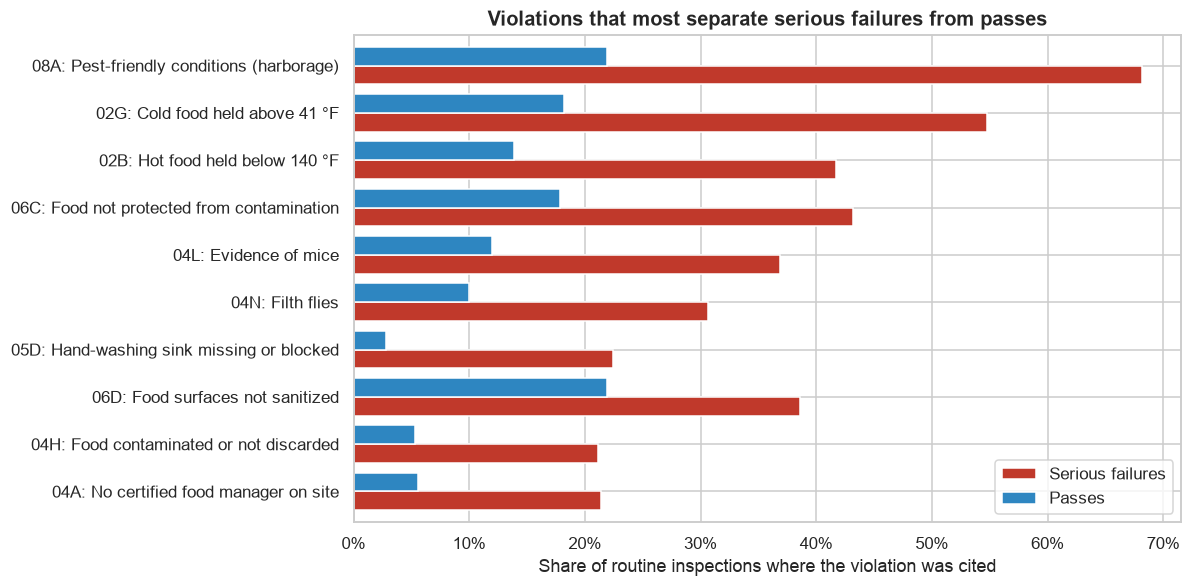

In [24]:
cycle_keys = model_df[["camis", "inspection_date", "fail"]]
cycle_violations = (df[df["inspection_type"] == "Cycle Inspection / Initial Inspection"]
                    .merge(cycle_keys, on=["camis", "inspection_date"]))
cycle_violations = cycle_violations.dropna(subset=["violation_code"])
share = (cycle_violations.drop_duplicates(["camis", "inspection_date", "violation_code"])
         .groupby(["violation_code", "fail"]).size().unstack(fill_value=0)
         .div(cycle_keys["fail"].value_counts(), axis=1))
share = share.assign(gap=share[1] - share[0]).nlargest(10, "gap")
short_labels = {"08A": "Pest-friendly conditions (harborage)", "02G": "Cold food held above 41 °F",
                "02B": "Hot food held below 140 °F", "06C": "Food not protected from contamination",
                "04L": "Evidence of mice", "04N": "Filth flies", "05D": "Hand-washing sink missing or blocked",
                "06D": "Food surfaces not sanitized", "04H": "Food contaminated or not discarded",
                "04A": "No certified food manager on site", "04M": "Live roaches", "04K": "Evidence of rats",
                "02H": "Food not cooled properly", "10F": "Non-food surfaces dirty or damaged"}
share.index = [f"{c}: {short_labels.get(c, c)}" for c in share.index]

fig, ax = plt.subplots(figsize=(11, 5.5))
share[[1, 0]].rename(columns={1: "Serious failures", 0: "Passes"}).iloc[::-1].plot.barh(
    ax=ax, color=[FAIL_COLOR, PASS_COLOR], width=0.8)
ax.set(title="Violations that most separate serious failures from passes",
       xlabel="Share of routine inspections where the violation was cited", ylabel="")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title=None, loc="lower right")
plt.tight_layout()
save_fig(fig, "violations_in_failures")
plt.show()

**Observations:** serious failures are driven by a familiar set of problems. **Pest-friendly conditions** appear in about two-thirds of serious failures vs about one in five passes, followed by **food held at unsafe temperatures** and **evidence of mice or flies**. These are the same violation families used to build the history features, which supports that choice.

## 8. Statistical tests: are these differences real?

Charts can show differences that are just noise. The tests below check whether each pattern is statistically significant (p < 0.05):

* **Chi-square test of independence** for categorical features vs. the failure outcome, with **Cramér's V** for strength (0 = no relationship, 1 = perfect).
* **Mann-Whitney U test** for numeric features, because their distributions are skewed and not normal.

In [25]:
def chi_square_test(data, col):
    """Chi-square test of independence between a categorical column and the fail target."""
    table = pd.crosstab(data[col], data["fail"])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return {"feature": col, "test": "Chi-square", "statistic": chi2, "p_value": p_value, "effect_size": cramers_v}


def mann_whitney_test(data, col):
    """Mann-Whitney U test comparing a numeric column between failures and passes."""
    sub = data.dropna(subset=[col])
    u_stat, p_value = stats.mannwhitneyu(sub.loc[sub["fail"] == 1, col], sub.loc[sub["fail"] == 0, col])
    # Rank-biserial correlation as an effect size
    effect = 1 - 2 * u_stat / ((sub["fail"] == 1).sum() * (sub["fail"] == 0).sum())
    return {"feature": col, "test": "Mann-Whitney U", "statistic": u_stat, "p_value": p_value, "effect_size": abs(effect)}


test_df = model_df.assign(pest_history=(model_df["prior_pest_visits"] > 0).astype(int),
                          closure_history=(model_df["prior_closed_visits"] > 0).astype(int))
results = pd.DataFrame([chi_square_test(test_df, c) for c in ["boro", "cuisine_group", "pest_history", "closure_history", "is_chain"]]
                       + [mann_whitney_test(test_df, c) for c in ["last_score", "prior_mean_score", "days_since_last_inspection"]])
results["significant (p < 0.05)"] = results["p_value"] < 0.05
results.style.format({"statistic": "{:,.1f}", "p_value": "{:.2e}", "effect_size": "{:.3f}"}).hide(axis="index")

feature,test,statistic,p_value,effect_size,significant (p < 0.05)
boro,Chi-square,142.9,6.66e-30,0.056,True
cuisine_group,Chi-square,"1,031.5",2.40e-210,0.150,True
pest_history,Chi-square,486.7,7.52e-108,0.103,True
closure_history,Chi-square,153.6,2.85e-35,0.058,True
is_chain,Chi-square,605.7,9.85e-134,0.115,True
last_score,Mann-Whitney U,"96,391,560.5",7.71e-162,0.223,True
prior_mean_score,Mann-Whitney U,"103,225,977.5",9.39e-308,0.310,True
days_since_last_inspection,Mann-Whitney U,"71,049,575.0",1.37e-36,0.104,True


**Interpretation:** every relationship tested is statistically significant (p far below 0.05), so the patterns in the charts are **not due to chance**. The effect sizes, however, are **small to moderate**: the strongest are the average earlier score (0.31) and the most recent earlier score (0.22), followed by cuisine (Cramér's V 0.15), chain status (0.11) and pest history (0.10). Borough is significant but weak (0.06). Each factor nudges the risk rather than deciding it, which again points to a model that combines them.

## 9. Save the modeling table

In [26]:
feature_cols = (["camis", "inspection_date", "fail", "score", "boro", "cuisine_group", "inspection_month", "inspection_dow",
                 "chain_size", "is_chain", "has_prior_inspection", "prev_cycle_score", "prev_cycle_fail", "days_since_prev_cycle"]
                + history_cols)
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
model_df[feature_cols].to_csv(PROCESSED_PATH, index=False, compression="gzip")
print(f"Saved {len(model_df):,} rows x {len(feature_cols)} columns to {PROCESSED_PATH}")

Saved 46,000 rows x 26 columns to ../data/processed/model_table.csv.gz


## 10. Summary of findings

**Data and cleaning**
* Started from 294,406 violation records (NYC Open Data snapshot, 25 Oct 2026). Removed 217 duplicate rows, 3,917 placeholder rows for not-yet-inspected restaurants and 2,255 rows from before 2022 (thin coverage). Fixed invalid coordinates (0,0) and borough codes, imputing them from ZIP codes.
* Rolled violations up to 91,745 inspections and kept **46,000 routine (cycle initial) inspections** of restaurants as prediction targets, after removing 77 zero-score inspections with critical violations (data-entry errors).
* Very high scores (up to 157 points) are genuine, coming with many violations and frequent closures, so they were kept. Score-history features were capped at the 99th percentile.

**What the data says**
* **18.1%** of routine inspections are serious failures (28+ points), an imbalanced target.
* **Past behavior is the strongest signal.** Restaurants whose last routine score was very high fail again 36% of the time vs 12% after an A-range score. Earlier pests (23% vs 13%) and closures (32% vs 17%) also raise the risk.
* **Chains fail about half as often** (9% vs 20%), and cuisine matters (Caribbean 29% vs Donuts 5%). Borough matters less (Queens 22% vs Staten Island 14%).
* All tested relationships are statistically significant but individually small, so the model must combine many weak signals.

**Engineered features** (all from earlier inspections only): previous routine score and result, most recent and average earlier score, earlier critical violations, counts of earlier visits with pests, temperature, hygiene and certificate problems, earlier closures, days since the last inspection, number of earlier inspections, chain size, cuisine group, borough, month and day of week.

**Next:** [Part 2](02_baseline_model.ipynb) uses this table to build and evaluate a baseline model.